<a href="https://colab.research.google.com/github/bgeethagayathri2-del/Titanic-survival-prediction/blob/main/Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape: (891, 15)
Missing values:
survived      0
pclass        0
sex           0
age         177
fare          0
embarked      2
dtype: int64


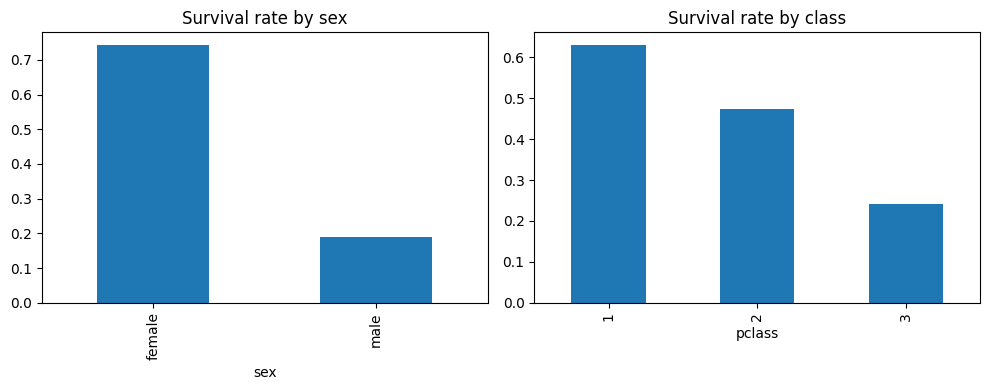

Logistic Regression accuracy: 0.81
Random Forest accuracy: 0.799
              precision    recall  f1-score   support

        Died       0.82      0.84      0.83       105
    Survived       0.76      0.74      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179

fare 0.274
sex 0.268
age 0.253
pclass 0.08
sibsp 0.055
parch 0.038
embarked_S 0.023
embarked_Q 0.01


In [1]:
# Titanic Survival Prediction
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Load data (891 passengers)
raw = sns.load_dataset("titanic")
print("Shape:", raw.shape)
print("Missing values:")
print(raw[["survived", "pclass", "sex", "age", "fare", "embarked"]].isnull().sum())

# 2. Quick exploration: who survived?
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
raw.groupby("sex")["survived"].mean().plot(kind="bar", ax=axes[0], title="Survival rate by sex")
raw.groupby("pclass")["survived"].mean().plot(kind="bar", ax=axes[1], title="Survival rate by class")
plt.tight_layout()
plt.show()

# 3. Clean the data
df = raw[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]].copy()
df["age"] = df["age"].fillna(df["age"].median())
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["sex"] = df["sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["embarked"], drop_first=True)

# 4. Split
X = df.drop("survived", axis=1)
y = df["survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Train two models
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

lr_acc = accuracy_score(y_test, lr.predict(X_test))
rf_acc = accuracy_score(y_test, rf.predict(X_test))
print("Logistic Regression accuracy:", round(lr_acc, 3))
print("Random Forest accuracy:", round(rf_acc, 3))

# 6. Detailed report for Random Forest
print(classification_report(y_test, rf.predict(X_test),
                            target_names=["Died", "Survived"]))

# 7. Most important features
for feature, score in sorted(zip(X.columns, rf.feature_importances_),
                             key=lambda x: -x[1]):
    print(feature, round(score, 3))